In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the dataset
df = pd.read_csv("../dataset/market_daily_sample.csv")
print("Original dataset loaded successfully!")

Original dataset loaded successfully!


In [3]:
# copy of the original dataset
df_clean = df.copy()
print("Dataset copy created successfully!")

Dataset copy created successfully!


In [4]:
# Check dimensions of two datasets
print("Original Dataset Shape:", df.shape)
print("Copied Dataset Shape:", df_clean.shape)

Original Dataset Shape: (275423, 8)
Copied Dataset Shape: (275423, 8)


In [5]:
# Check missing values in each column
print("Missing Values in Each Column:")
print(df_clean.isnull().sum())

Missing Values in Each Column:
date                  0
commodity             0
state                 0
district              0
market                0
mkt_id                0
arrival_t             0
modal_price_rs_qtl    0
dtype: int64


In [6]:
# Check is there any duplicate records in the dataset
duplicate_count = df_clean.duplicated().sum()
print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [7]:
# Check negative values in the  columns
print("Negative Arrival Values:",
      (df_clean['arrival_t'] < 0).sum())

print("Negative Modal Price Values:",
      (df_clean['modal_price_rs_qtl'] < 0).sum())

Negative Arrival Values: 0
Negative Modal Price Values: 0


In [8]:
# Check zero values in the  columns
print("Zero Arrival Values:",
      (df_clean['arrival_t'] == 0).sum())

print("Zero Modal Price Values:",
      (df_clean['modal_price_rs_qtl'] == 0).sum())

Zero Arrival Values: 289
Zero Modal Price Values: 0


In [9]:
# Inspect records having zero arrival quantity
zero_arrival_records = df_clean[df_clean['arrival_t'] == 0]
print("Total Zero Arrival Records:",
      len(zero_arrival_records))
display(zero_arrival_records.head(10))

Total Zero Arrival Records: 289


,date,commodity,state,district,market,mkt_id,arrival_t,modal_price_rs_qtl
9367,2025-11-13,Paddy(Common),Telangana,Karimnagar,Huzzurabad APMC,890,0.0,2369.0
9368,2025-11-13,Paddy(Common),Telangana,Karimnagar,Manakodur APMC,3762,0.0,2369.0
13940,2025-11-19,Paddy(Common),Telangana,Karimnagar,Manakodur APMC,3762,0.0,2369.0
13949,2025-11-19,Paddy(Common),Telangana,Nalgonda,Devarakonda APMC,866,0.0,2400.0
13950,2025-11-19,Paddy(Common),Telangana,Nalgonda,Miryalaguda APMC,12,0.0,2389.0
18617,2025-11-25,Paddy(Common),Telangana,Karimnagar,Manakodur APMC,3762,0.0,2369.0
18624,2025-11-25,Paddy(Common),Telangana,Nalgonda,Devarakonda APMC,866,0.0,2400.0
18625,2025-11-25,Paddy(Common),Telangana,Nalgonda,Miryalaguda APMC,12,0.0,2389.0
22476,2025-12-01,Bajra(Pearl Millet/Cumbu),Madhya Pradesh,Chhindwara,Chhindwara APMC,517,0.0,1500.0
23204,2025-12-01,Paddy(Common),Telangana,Karimnagar,Huzzurabad APMC,890,0.0,2369.0


In [10]:
# Analyze zero arrival records commodity-wise
zero_arrival_commodity = zero_arrival_records['commodity'].value_counts()
print("Zero Arrival Records by Commodity:")
display(zero_arrival_commodity)

Zero Arrival Records by Commodity:


commodity
Paddy(Common)                177
Cotton                        31
Tomato                        30
Onion                         24
Potato                        21
Maize                          3
Garlic                         2
Bajra(Pearl Millet/Cumbu)      1
Name: count, dtype: int64

In [11]:
# Analyze zero arrival records state-wise
zero_arrival_state = zero_arrival_records['state'].value_counts()
print("Zero Arrival Records by State:")
display(zero_arrival_state)

Zero Arrival Records by State:


state
Telangana         207
Keralam            57
Punjab             13
Madhya Pradesh      5
Andhra Pradesh      3
Uttar Pradesh       2
Bihar               2
Name: count, dtype: int64

In [12]:
# Check data types of all columns
print("Data Types of Each Column:")
print(df_clean.dtypes)

Data Types of Each Column:
date                      str
commodity                 str
state                     str
district                  str
market                    str
mkt_id                  int64
arrival_t             float64
modal_price_rs_qtl    float64
dtype: object


In [13]:
# Convert date column into datetime format
df_clean['date'] = pd.to_datetime(df_clean['date'])
print("Date column converted successfully!")
print(df_clean.dtypes)

Date column converted successfully!
date                  datetime64[us]
commodity                        str
state                            str
district                         str
market                           str
mkt_id                         int64
arrival_t                    float64
modal_price_rs_qtl           float64
dtype: object


In [14]:
# Verifying that conversion
print("Date Column Data Type:", df_clean['date'].dtype)
print("\nFirst 5 Dates:")
display(df_clean['date'].head())

Date Column Data Type: datetime64[us]

First 5 Dates:


0   2025-11-01
1   2025-11-01
2   2025-11-01
3   2025-11-01
4   2025-11-01
Name: date, dtype: datetime64[us]

In [15]:
# Check the missing dates after conversion
print("Missing Dates:",
      df_clean['date'].isnull().sum())

Missing Dates: 0


In [16]:
# Display numerical column statistics
print("Numerical Data Summary:")
display(df_clean[['arrival_t', 'modal_price_rs_qtl']].describe())

Numerical Data Summary:


,arrival_t,modal_price_rs_qtl
count,275423.000000,275423.000000
mean,100.178665,4058.698170
std,974.721257,3526.553796
min,0.000000,0.010000
25%,0.800000,2000.000000
50%,5.900000,2724.090000
75%,38.000000,5525.000000
max,143065.100000,58600.000000


In [17]:
# Calculate IQR for Arrival Quantity

Q1_arrival = df_clean['arrival_t'].quantile(0.25)
Q3_arrival = df_clean['arrival_t'].quantile(0.75)
IQR_arrival = Q3_arrival - Q1_arrival
lower_arrival = Q1_arrival - 1.5 * IQR_arrival
upper_arrival = Q3_arrival + 1.5 * IQR_arrival

print("Arrival IQR:", IQR_arrival)
print("Lower Bound:", lower_arrival)
print("Upper Bound:", upper_arrival)
outliers_arrival = df_clean[
    (df_clean['arrival_t'] < lower_arrival) |
    (df_clean['arrival_t'] > upper_arrival)
]
print("Total Arrival Outliers:", len(outliers_arrival))

Arrival IQR: 37.2
Lower Bound: -55.00000000000001
Upper Bound: 93.80000000000001
Total Arrival Outliers: 40968


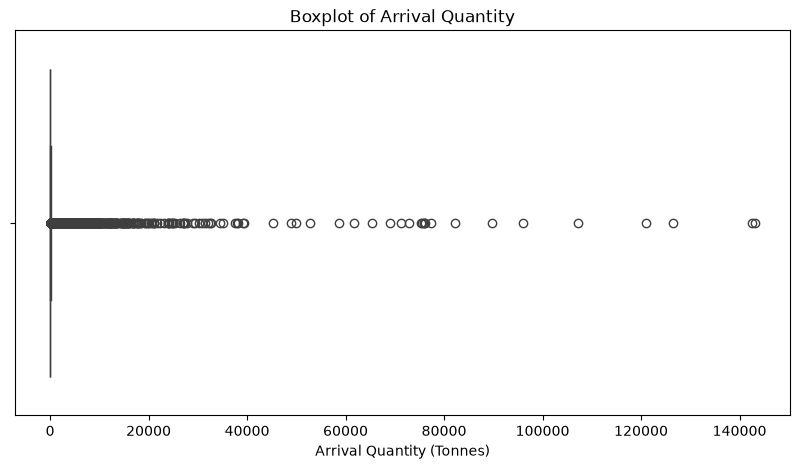

In [ ]:
# Visualize outliers in Arrival Quantity

plt.figure(figsize=(10, 5))
sns.boxplot(x=df_clean['arrival_t'])

plt.title("Boxplot of Arrival Quantity")
plt.xlabel("Arrival Quantity (Tonnes)")

plt.show()

In [20]:
# Calculate IQR for Modal Price
Q1_price = df_clean['modal_price_rs_qtl'].quantile(0.25)
Q3_price = df_clean['modal_price_rs_qtl'].quantile(0.75)
IQR_price = Q3_price - Q1_price

lower_price = Q1_price - 1.5 * IQR_price
upper_price = Q3_price + 1.5 * IQR_price

print("Modal Price IQR:", IQR_price)
print("Lower Bound:", lower_price)
print("Upper Bound:", upper_price)

outliers_price = df_clean[
    (df_clean['modal_price_rs_qtl'] < lower_price) |
    (df_clean['modal_price_rs_qtl'] > upper_price)
]

print("Total Modal Price Outliers:", len(outliers_price))

Modal Price IQR: 3525.0
Lower Bound: -3287.5
Upper Bound: 10812.5
Total Modal Price Outliers: 10358


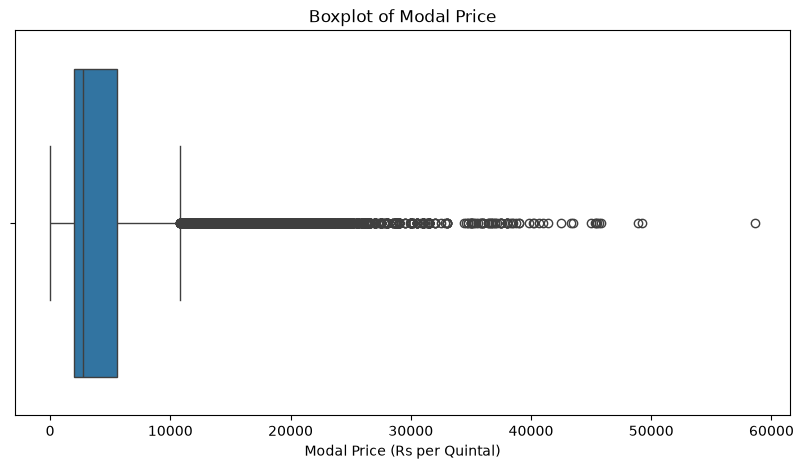

In [21]:
# Visualize outliers in Modal Price

plt.figure(figsize=(10, 5))
sns.boxplot(x=df_clean['modal_price_rs_qtl'])

plt.title("Boxplot of Modal Price")
plt.xlabel("Modal Price (Rs per Quintal)")

plt.show()

In [22]:
# Check minimum and maximum modal prices
print("Minimum Modal Price:",
      df_clean['modal_price_rs_qtl'].min())

print("Maximum Modal Price:",
      df_clean['modal_price_rs_qtl'].max())

print("Median Modal Price:",
      df_clean['modal_price_rs_qtl'].median())

print("Mean Modal Price:",
      df_clean['modal_price_rs_qtl'].mean())

Minimum Modal Price: 0.01
Maximum Modal Price: 58600.0
Median Modal Price: 2724.09
Mean Modal Price: 4058.6981703053125


In [23]:
# Inspect top 10 highest modal price records

highest_prices = df_clean.sort_values(
    by='modal_price_rs_qtl',
    ascending=False
).head(10)

print("Top 10 Highest Modal Price Records:")

display(highest_prices)

Top 10 Highest Modal Price Records:


,date,commodity,state,district,market,mkt_id,arrival_t,modal_price_rs_qtl
74517,2026-02-17,Dry Chillies,Karnataka,Chikkamagaluru,Tarikere APMC,503,4.1,58600.00
141345,2026-05-12,Dry Chillies,Karnataka,Dharwad,APMC Hubballi,108,5.1,49200.00
105335,2026-03-31,Dry Chillies,Karnataka,Dharwad,APMC Hubballi,108,3.6,48889.00
261321,2026-10-09,Dry Chillies,Karnataka,Haveri,Byadagi APMC,349,246.4,45838.06
147250,2026-05-18,Dry Chillies,Karnataka,Bengaluru,Bengaluru APMC,99,3.0,45616.67
91408,2026-03-13,Dry Chillies,Karnataka,Dharwad,APMC Hubballi,108,0.3,45500.00
267606,2026-10-15,Dry Chillies,Karnataka,Haveri,Byadagi APMC,349,258.1,45438.06
255255,2026-10-03,Dry Chillies,Karnataka,Haveri,Byadagi APMC,349,235.1,45332.05
241318,2026-09-15,Dry Chillies,Karnataka,Shivamogga,Shimoga APMC,753,0.2,45000.00
210114,2026-08-04,Dry Chillies,Karnataka,Shivamogga,Shimoga APMC,753,0.3,43500.00


In [24]:
# Inspect top 10 lowest modal price records

lowest_prices = df_clean.sort_values(
    by='modal_price_rs_qtl',
    ascending=True
).head(10)
print("Top 10 Lowest Modal Price Records:")
display(lowest_prices)

Top 10 Lowest Modal Price Records:


,date,commodity,state,district,market,mkt_id,arrival_t,modal_price_rs_qtl
262599,2026-10-09,Potato,Punjab,Tarntaran,Patti APMC,598,0.65,0.01
251802,2026-09-27,Tomato,Punjab,Tarntaran,Patti APMC,598,0.10,0.01
248309,2026-09-21,Potato,Punjab,Tarntaran,Patti APMC,598,0.60,0.01
268270,2026-10-15,Onion,Punjab,Tarntaran,Patti APMC,598,0.58,0.01
273881,2026-10-21,Onion,Punjab,Tarntaran,Patti APMC,598,0.68,0.01
256461,2026-10-03,Potato,Punjab,Tarntaran,Patti APMC,598,0.68,0.01
249096,2026-09-21,Tomato,Punjab,Tarntaran,Patti APMC,598,0.10,0.01
257191,2026-10-03,Tomato,Punjab,Tarntaran,Patti APMC,598,0.10,0.01
268897,2026-10-15,Potato,Punjab,Tarntaran,Patti APMC,598,0.56,0.01
251230,2026-09-27,Potato,Punjab,Tarntaran,Patti APMC,598,0.70,0.01


In [25]:
# Count records having modal price equal to 0.01

low_price_records = df_clean[
    df_clean['modal_price_rs_qtl'] == 0.01
]
print("Total Records with Rs 0.01 Price:",
      len(low_price_records))
print("\nCommodity-wise Count:")
display(low_price_records['commodity'].value_counts())
print("\nState-wise Count:")
display(low_price_records['state'].value_counts())

Total Records with Rs 0.01 Price: 13

Commodity-wise Count:


commodity
Potato    6
Tomato    5
Onion     2
Name: count, dtype: int64


State-wise Count:


state
Punjab    13
Name: count, dtype: int64

In [26]:
# Inspect all records having modal price equal to 0.01
display(
    low_price_records[
        ['date', 'commodity', 'state', 'district',
         'market', 'arrival_t', 'modal_price_rs_qtl']
    ]
)

,date,commodity,state,district,market,arrival_t,modal_price_rs_qtl
248309,2026-09-21,Potato,Punjab,Tarntaran,Patti APMC,0.60,0.01
249096,2026-09-21,Tomato,Punjab,Tarntaran,Patti APMC,0.10,0.01
251230,2026-09-27,Potato,Punjab,Tarntaran,Patti APMC,0.70,0.01
251802,2026-09-27,Tomato,Punjab,Tarntaran,Patti APMC,0.10,0.01
256461,2026-10-03,Potato,Punjab,Tarntaran,Patti APMC,0.68,0.01
257191,2026-10-03,Tomato,Punjab,Tarntaran,Patti APMC,0.10,0.01
262599,2026-10-09,Potato,Punjab,Tarntaran,Patti APMC,0.65,0.01
268270,2026-10-15,Onion,Punjab,Tarntaran,Patti APMC,0.58,0.01
268897,2026-10-15,Potato,Punjab,Tarntaran,Patti APMC,0.56,0.01
269695,2026-10-15,Tomato,Punjab,Tarntaran,Patti APMC,0.10,0.01


In [27]:
# Investigate all records from Patti APMC
patti_records = df_clean[
    df_clean['market'] == 'Patti APMC'
]
print("Total Patti APMC Records:", len(patti_records))
print("\nModal Price Statistics:")
display(patti_records['modal_price_rs_qtl'].describe())
print("\nCommodity-wise Price Analysis:")
display(
    patti_records.groupby('commodity')['modal_price_rs_qtl']
    .agg(['count', 'min', 'median', 'max'])
)

Total Patti APMC Records: 144

Modal Price Statistics:


count     144.000000
mean      744.169444
std      1374.397809
min         0.010000
25%         1.000000
50%       100.000000
75%       800.150000
max      9050.000000
Name: modal_price_rs_qtl, dtype: float64


Commodity-wise Price Analysis:


,count,min,median,max
commodity,,,,
Garlic,22,6.50,1250.0,9050.0
Onion,37,0.01,45.0,1400.0
Paddy(Common),3,2461.00,2461.0,2461.0
Potato,37,0.01,5.4,1150.0
Tomato,42,0.01,110.0,4500.0
Wheat,3,2585.00,2585.0,2585.0


In [28]:
# Calculate percentage of records with suspicious prices
total_records = len(df_clean)
suspicious_records = len(low_price_records)
percentage = (suspicious_records / total_records) * 100
print("Total Dataset Records:", total_records)
print("Records with Rs 0.01 Price:",
      suspicious_records)
print("Percentage of Suspicious Records:",
      round(percentage, 4), "%")

Total Dataset Records: 275423
Records with Rs 0.01 Price: 13
Percentage of Suspicious Records: 0.0047 %


In [29]:
# Analyze modal prices of zero-arrival records

print("Modal Price Statistics for Zero Arrival Records:")
display(
    zero_arrival_records['modal_price_rs_qtl'].describe()
)
print("\nFirst 10 Zero Arrival Records with Prices:")
display(
    zero_arrival_records[
        ['date', 'commodity', 'state', 'market',
         'arrival_t', 'modal_price_rs_qtl']
    ].head(10)
)

Modal Price Statistics for Zero Arrival Records:


count      289.000000
mean      3368.607543
std       1843.901114
min        400.000000
25%       2369.000000
50%       2389.000000
75%       3800.000000
max      14038.910000
Name: modal_price_rs_qtl, dtype: float64


First 10 Zero Arrival Records with Prices:


,date,commodity,state,market,arrival_t,modal_price_rs_qtl
9367,2025-11-13,Paddy(Common),Telangana,Huzzurabad APMC,0.0,2369.0
9368,2025-11-13,Paddy(Common),Telangana,Manakodur APMC,0.0,2369.0
13940,2025-11-19,Paddy(Common),Telangana,Manakodur APMC,0.0,2369.0
13949,2025-11-19,Paddy(Common),Telangana,Devarakonda APMC,0.0,2400.0
13950,2025-11-19,Paddy(Common),Telangana,Miryalaguda APMC,0.0,2389.0
18617,2025-11-25,Paddy(Common),Telangana,Manakodur APMC,0.0,2369.0
18624,2025-11-25,Paddy(Common),Telangana,Devarakonda APMC,0.0,2400.0
18625,2025-11-25,Paddy(Common),Telangana,Miryalaguda APMC,0.0,2389.0
22476,2025-12-01,Bajra(Pearl Millet/Cumbu),Madhya Pradesh,Chhindwara APMC,0.0,1500.0
23204,2025-12-01,Paddy(Common),Telangana,Huzzurabad APMC,0.0,2369.0


In [30]:
# Analyze records with positive arrival quantity
positive_arrival_records = df_clean[
    df_clean['arrival_t'] > 0
]
print("Total Positive Arrival Records:",
      len(positive_arrival_records))
print("Percentage of Positive Arrival Records:",
      round((len(positive_arrival_records) / len(df_clean)) * 100, 2),
      "%")

Total Positive Arrival Records: 275134
Percentage of Positive Arrival Records: 99.9 %


In [31]:
# Analyze positive arrival quantity records
print("Positive Arrival Quantity Statistics:")

display(
    positive_arrival_records['arrival_t'].describe()
)

Positive Arrival Quantity Statistics:


count    275134.000000
mean        100.283893
std         975.227637
min           0.010000
25%           0.810000
50%           5.900000
75%          38.100000
max      143065.100000
Name: arrival_t, dtype: float64

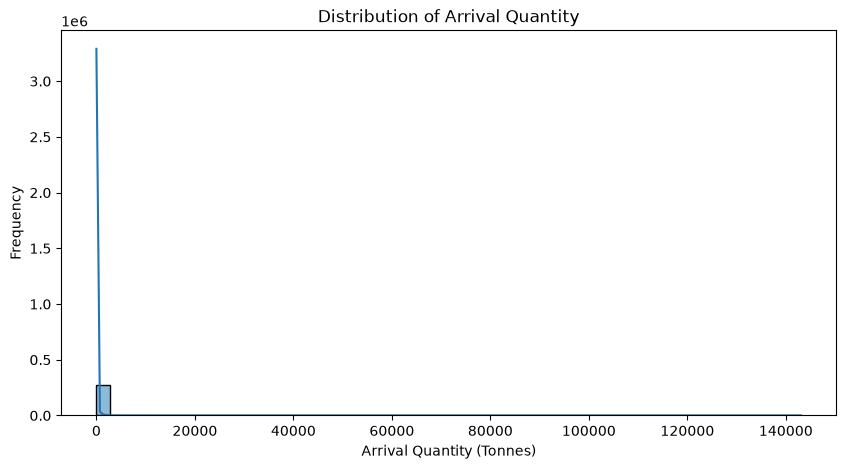

In [32]:
# Visualize distribution of arrival quantity
plt.figure(figsize=(10, 5))
sns.histplot(
    data=positive_arrival_records,
    x='arrival_t',
    bins=50,
    kde=True
)
plt.title("Distribution of Arrival Quantity")
plt.xlabel("Arrival Quantity (Tonnes)")
plt.ylabel("Frequency")
plt.show()

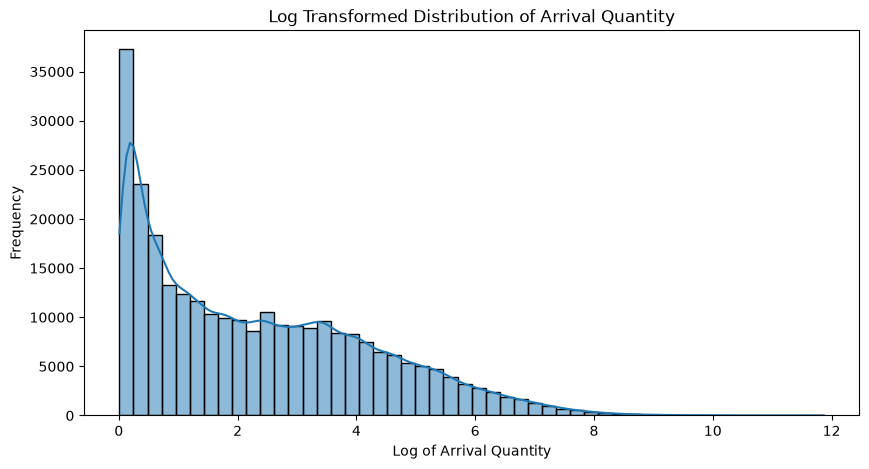

In [33]:
# Visualize arrival quantity using log transformation

plt.figure(figsize=(10, 5))
sns.histplot(
    np.log1p(positive_arrival_records['arrival_t']),
    bins=50,
    kde=True
)
plt.title("Log Transformed Distribution of Arrival Quantity")
plt.xlabel("Log of Arrival Quantity")
plt.ylabel("Frequency")

plt.show()

In [34]:
# Calculate outliers after log transformation

log_arrival = np.log1p(positive_arrival_records['arrival_t'])
Q1_log = log_arrival.quantile(0.25)
Q3_log = log_arrival.quantile(0.75)

IQR_log = Q3_log - Q1_log

lower_log = Q1_log - 1.5 * IQR_log
upper_log = Q3_log + 1.5 * IQR_log

log_outliers = log_arrival[
    (log_arrival < lower_log) |
    (log_arrival > upper_log)
]

print("Lower Bound:", lower_log)
print("Upper Bound:", upper_log)
print("Total Log Transformed Outliers:", len(log_outliers))

Lower Bound: -4.015866587292645
Upper Bound: 8.275315899561699
Total Log Transformed Outliers: 620


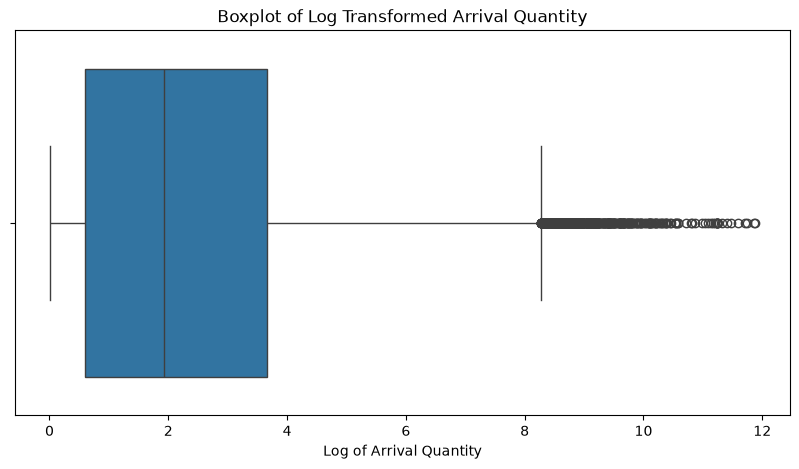

In [35]:
# Visualize outliers after log transformation
plt.figure(figsize=(10, 5))
sns.boxplot(x=log_arrival)
plt.title("Boxplot of Log Transformed Arrival Quantity")
plt.xlabel("Log of Arrival Quantity")
plt.show()

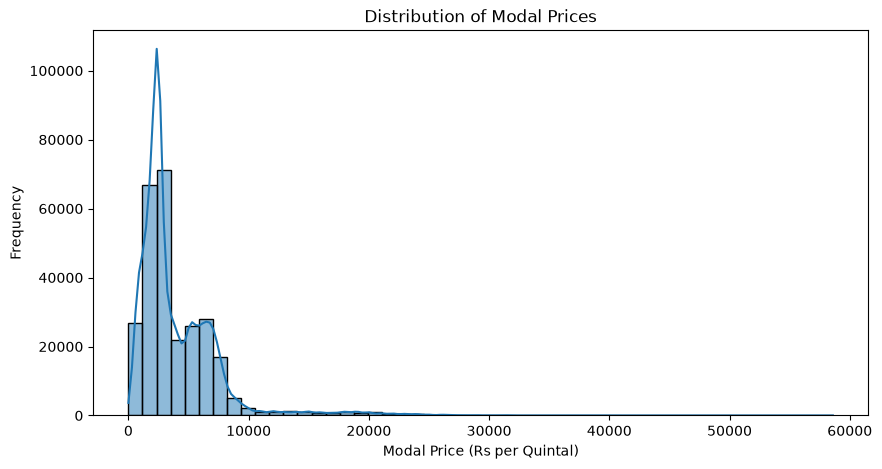

In [36]:
# Visualize distribution of modal prices

plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_clean,
    x='modal_price_rs_qtl',
    bins=50,
    kde=True
)
plt.title("Distribution of Modal Prices")
plt.xlabel("Modal Price (Rs per Quintal)")
plt.ylabel("Frequency")

plt.show()

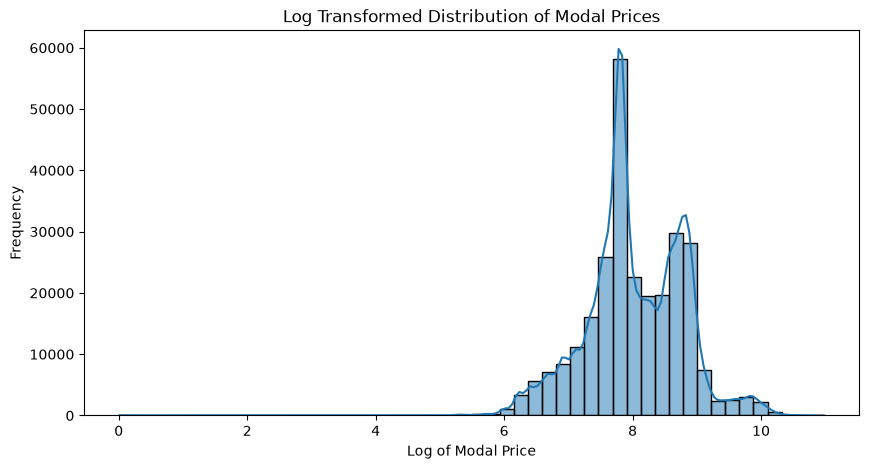

In [37]:
# Log transformation of modal prices

log_price = np.log1p(df_clean['modal_price_rs_qtl'])
plt.figure(figsize=(10, 5))
sns.histplot(log_price, bins=50, kde=True)
plt.title("Log Transformed Distribution of Modal Prices")
plt.xlabel("Log of Modal Price")
plt.ylabel("Frequency")

plt.show()

In [38]:
# Calculate outliers after log transformation of modal prices
Q1_price_log = log_price.quantile(0.25)
Q3_price_log = log_price.quantile(0.75)
IQR_price_log = Q3_price_log - Q1_price_log

lower_price_log = Q1_price_log - 1.5 * IQR_price_log
upper_price_log = Q3_price_log + 1.5 * IQR_price_log

log_price_outliers = log_price[
    (log_price < lower_price_log) |
    (log_price > upper_price_log)
]

print("Lower Bound:", lower_price_log)
print("Upper Bound:", upper_price_log)
print("Total Log Price Outliers:", len(log_price_outliers))

Lower Bound: 6.07767657823429
Upper Bound: 10.140945261832805
Total Log Price Outliers: 2081


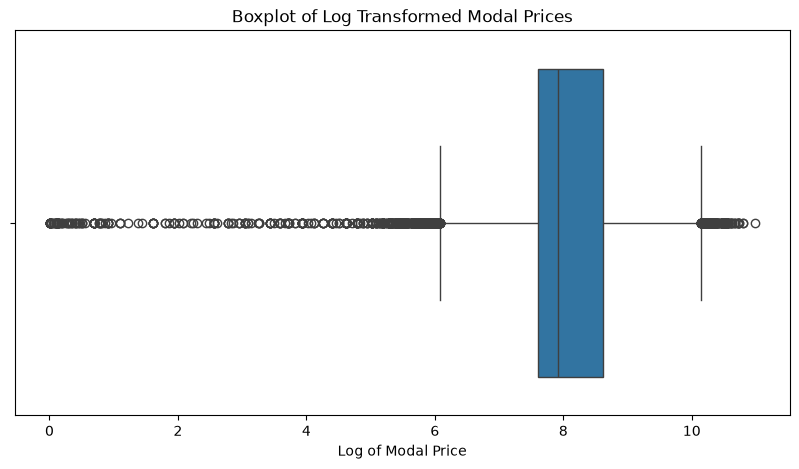

In [39]:
# Visualize outliers after log transformation of modal prices
plt.figure(figsize=(10, 5))
sns.boxplot(x=log_price)

plt.title("Boxplot of Log Transformed Modal Prices")
plt.xlabel("Log of Modal Price")

plt.show()

In [40]:
# Count lower and upper price outliers separately

lower_price_outliers = log_price[
    log_price < lower_price_log
]
upper_price_outliers = log_price[
    log_price > upper_price_log
]
print("Lower Price Outliers:",
      len(lower_price_outliers))
print("Upper Price Outliers:",
      len(upper_price_outliers))
print("Total Price Outliers:",
      len(log_price_outliers))

Lower Price Outliers: 1549
Upper Price Outliers: 532
Total Price Outliers: 2081


In [41]:
# Inspect lower price outlier records

lower_price_indices = lower_price_outliers.index
display(
    df_clean.loc[
        lower_price_indices,
        ['date', 'commodity', 'state', 'district',
         'market', 'arrival_t', 'modal_price_rs_qtl']
    ].head(20)
)

,date,commodity,state,district,market,arrival_t,modal_price_rs_qtl
3093,2025-11-01,Onion,Madhya Pradesh,Dewas,Sonkatch APMC,68.20,404.50
3099,2025-11-01,Onion,Madhya Pradesh,Indore,Gautampura APMC,86.20,300.00
3112,2025-11-01,Onion,Madhya Pradesh,Rajgarh,Sarangpur APMC,57.20,400.00
3120,2025-11-01,Onion,Madhya Pradesh,Sehore,Ashta APMC,22.54,101.00
3126,2025-11-01,Onion,Madhya Pradesh,Shajapur,Shujalpur APMC,242.40,100.00
3129,2025-11-01,Onion,Madhya Pradesh,Ujjain,Badnagar APMC,87.50,400.00
3151,2025-11-01,Onion,Maharashtra,Jalna,APMC Jalana,15.60,400.00
3655,2025-11-01,Potato,Gujarat,Rajkot,Gondal(Veg.market Gondal) APMC,45.75,400.00
4218,2025-11-01,Tomato,Andhra Pradesh,Ananthapuramu,Anantapur APMC,1275.00,160.00
7566,2025-11-07,Onion,Madhya Pradesh,Dewas,Sonkatch APMC,85.50,403.00


In [42]:
# Inspect upper price outlier records

upper_price_indices = upper_price_outliers.index
display(
    df_clean.loc[
        upper_price_indices,
        ['date', 'commodity', 'state', 'district',
         'market', 'arrival_t', 'modal_price_rs_qtl']
    ].head(20)
)

,date,commodity,state,district,market,arrival_t,modal_price_rs_qtl
30642,2025-12-13,Turmeric,Meghalaya,East Jaintia Hills,Khliehriat APMC,0.1,29000.00
34464,2025-12-19,Cummin Seed(Jeera),Assam,Kamrup,Fancy Bazaar APMC,2.5,36000.00
34495,2025-12-19,Dry Chillies,Assam,Kamrup,Fancy Bazaar APMC,0.3,28000.00
37860,2025-12-25,Cummin Seed(Jeera),Assam,Kamrup,Fancy Bazaar APMC,5.0,36700.00
37878,2025-12-25,Cummin Seed(Jeera),Rajasthan,Jodhpur,Jodhpur (Grain) APMC,46.8,35800.36
37882,2025-12-25,Dry Chillies,Assam,Kamrup,Fancy Bazaar APMC,0.4,28000.00
42150,2025-12-31,Cummin Seed(Jeera),Assam,Kamrup,Fancy Bazaar APMC,6.0,34800.00
42176,2025-12-31,Cummin Seed(Jeera),Rajasthan,Jodhpur,Jodhpur (Grain) APMC,50.9,36654.91
42181,2025-12-31,Dry Chillies,Assam,Kamrup,Fancy Bazaar APMC,0.5,29000.00
46881,2026-01-06,Cummin Seed(Jeera),Assam,Kamrup,Fancy Bazaar APMC,10.0,34600.00


In [43]:
# Analyze upper price outliers commodity-wise
upper_outlier_records = df_clean.loc[upper_price_outliers.index]
print("Upper Price Outliers by Commodity:")
display(
    upper_outlier_records.groupby('commodity')['modal_price_rs_qtl']
    .agg(['count', 'min', 'mean', 'max'])
    .sort_values(by='count', ascending=False)
)

Upper Price Outliers by Commodity:


,count,min,mean,max
commodity,,,,
Garlic,297,25500.00,27398.518519,42500.00
Dry Chillies,130,25533.00,32435.527000,58600.00
Cummin Seed(Jeera),97,25360.00,29974.453711,39800.00
Turmeric,7,25600.00,29267.214286,35600.00
Mustard,1,31340.28,31340.280000,31340.28


In [44]:
# Analyze upper price outliers state-wise
upper_outlier_state = upper_outlier_records['state'].value_counts()
print("Upper Price Outliers by State:")
display(upper_outlier_state)

Upper Price Outliers by State:


state
Tamil Nadu        275
Assam              90
Karnataka          58
Maharashtra        31
Manipur            21
Rajasthan          17
Keralam            16
Uttar Pradesh      10
Gujarat             7
Madhya Pradesh      3
Andhra Pradesh      2
Meghalaya           1
Chattisgarh         1
Name: count, dtype: int64

In [45]:
# Analyze lower price outliers state-wise
lower_outlier_records = df_clean.loc[lower_price_outliers.index]
lower_outlier_state = lower_outlier_records['state'].value_counts()
print("Lower Price Outliers by State:")
display(lower_outlier_state)

Lower Price Outliers by State:


state
Punjab               521
Haryana              395
Uttar Pradesh        245
Madhya Pradesh       212
Uttarakhand           49
West Bengal           31
Gujarat               25
Rajasthan             18
Chandigarh            17
Maharashtra           10
Karnataka              8
Telangana              6
NCT of Delhi           5
Chattisgarh            3
Andhra Pradesh         2
Jammu and Kashmir      2
Name: count, dtype: int64

In [46]:
# Analyze lower price outliers commodity-wise
lower_outlier_commodity = lower_outlier_records['commodity'].value_counts()
print("Lower Price Outliers by Commodity:")
display(lower_outlier_commodity)

Lower Price Outliers by Commodity:


commodity
Potato            1150
Onion              214
Tomato             170
Garlic              12
Maize                2
Jowar(Sorghum)       1
Name: count, dtype: int64

In [47]:
# Analyze lower price outliers market-wise
lower_outlier_market = lower_outlier_records['market'].value_counts().head(10)
print("Top 10 Markets with Lower Price Outliers:")
display(lower_outlier_market)

Top 10 Markets with Lower Price Outliers:


market
Rania APMC                        113
Patti APMC                         97
Rania(Jiwan nagar) APMC            75
Jalandhar City(Jalandhar) APMC     45
Patiala APMC                       43
Ludhiana APMC                      42
Kicchha APMC                       28
Morena APMC                        27
Bhehjoi APMC                       23
Morena(F&V) APMC                   23
Name: count, dtype: int64

In [48]:
# Compare lower and upper price outliers

print("Lower Price Outliers:", len(lower_price_outliers))
print("Upper Price Outliers:", len(upper_price_outliers))
print("Total Price Outliers:", len(log_price_outliers))
print("Lower Outlier Percentage:",
      round(len(lower_price_outliers) / len(log_price) * 100, 2), "%")

print("Upper Outlier Percentage:",
      round(len(upper_price_outliers) / len(log_price) * 100, 2), "%")

Lower Price Outliers: 1549
Upper Price Outliers: 532
Total Price Outliers: 2081
Lower Outlier Percentage: 0.56 %
Upper Outlier Percentage: 0.19 %


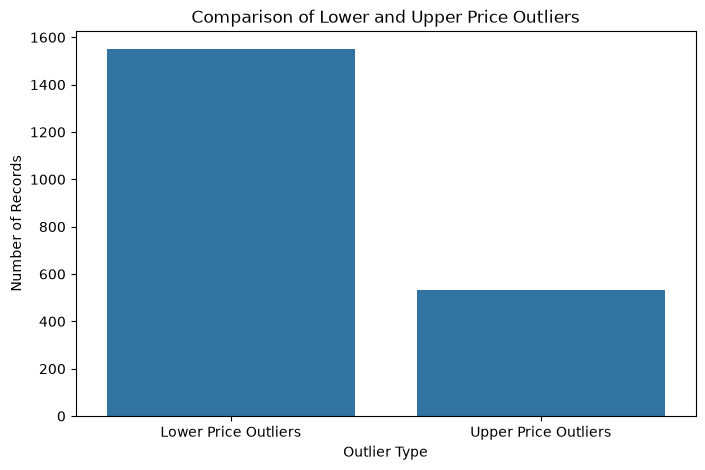

In [49]:
# Visualize lower and upper price outliers
outlier_counts = pd.Series({
    'Lower Price Outliers': len(lower_price_outliers),
    'Upper Price Outliers': len(upper_price_outliers)
})
plt.figure(figsize=(8, 5))
sns.barplot(
    x=outlier_counts.index,
    y=outlier_counts.values
)
plt.title("Comparison of Lower and Upper Price Outliers")
plt.xlabel("Outlier Type")
plt.ylabel("Number of Records")
plt.show()

In [50]:
# Calculate total price outlier percentage

total_price_outliers = len(log_price_outliers)
total_records = len(df_clean)
outlier_percentage = (
    total_price_outliers / total_records
) * 100
print("Total Records:", total_records)
print("Total Price Outliers:", total_price_outliers)
print("Price Outlier Percentage:",
      round(outlier_percentage, 4), "%")

Total Records: 275423
Total Price Outliers: 2081
Price Outlier Percentage: 0.7556 %


In [53]:
# Remove modal price outliers from the dataset
df_price_clean = df_clean.drop(
    index=log_price_outliers.index
)
print("Original Dataset Shape:", df_clean.shape)
print("Cleaned Dataset Shape:", df_price_clean.shape)
print("Remaining Price Outliers:",
      len(log_price_outliers.index.intersection(
          df_price_clean.index
      )))

Original Dataset Shape: (275423, 8)
Cleaned Dataset Shape: (273342, 8)
Remaining Price Outliers: 0


In [54]:
# Verify the cleaned dataset

print("Cleaned Dataset Information:")
df_price_clean.info()
print("\nMissing Values:")
print(df_price_clean.isnull().sum())
print("\nDuplicate Records:",
      df_price_clean.duplicated().sum())

Cleaned Dataset Information:
<class 'pandas.DataFrame'>
Index: 273342 entries, 0 to 275422
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   date                273342 non-null  datetime64[us]
 1   commodity           273342 non-null  str           
 2   state               273342 non-null  str           
 3   district            273342 non-null  str           
 4   market              273342 non-null  str           
 5   mkt_id              273342 non-null  int64         
 6   arrival_t           273342 non-null  float64       
 7   modal_price_rs_qtl  273342 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 18.8 MB

Missing Values:
date                  0
commodity             0
state                 0
district              0
market                0
mkt_id                0
arrival_t             0
modal_price_rs_qtl    0
dtype: int64

Duplic

In [55]:
# Compare original and cleaned modal prices
comparison = pd.DataFrame({
    'Original Dataset': df_clean['modal_price_rs_qtl'].describe(),
    'Cleaned Dataset': df_price_clean['modal_price_rs_qtl'].describe()
})
print("Original vs Cleaned Modal Price Comparison:")
display(comparison)

Original vs Cleaned Modal Price Comparison:


,Original Dataset,Cleaned Dataset
count,275423.000000,273342.000000
mean,4058.698170,4031.194730
std,3526.553796,3345.268475
min,0.010000,435.290000
25%,2000.000000,2000.000000
50%,2724.090000,2750.000000
75%,5525.000000,5525.000000
max,58600.000000,25255.000000


In [ ]:
# Save cleaned dataset
df_price_clean.to_csv(
    "../dataset/mandi_cleaned.csv",
    index=False
)
print("Cleaned dataset saved successfully!")
print("Final Dataset Shape:", df_price_clean.shape)

Cleaned dataset saved successfully!
Final Dataset Shape: (273342, 8)


In [57]:
# Final Data Preprocessing Summary

print("========== DATA PREPROCESSING SUMMARY ==========")
print("Original Dataset Records:", len(df_clean))
print("Cleaned Dataset Records:", len(df_price_clean))
print("Removed Records:",
      len(df_clean) - len(df_price_clean))
print("Missing Values:",
      df_price_clean.isnull().sum().sum())
print("Duplicate Records:",
      df_price_clean.duplicated().sum())
print("Final Dataset Columns:",
      df_price_clean.shape[1])
print("Final Dataset Shape:",
      df_price_clean.shape)
print("\nData Preprocessing Completed Successfully!")

========== DATA PREPROCESSING SUMMARY ==========
Original Dataset Records: 275423
Cleaned Dataset Records: 273342
Removed Records: 2081
Missing Values: 0
Duplicate Records: 0
Final Dataset Columns: 8
Final Dataset Shape: (273342, 8)

Data Preprocessing Completed Successfully!


In [58]:

# Check the final cleaned dataset
print("Dataset Shape:", df_price_clean.shape)
print("\nDataset Columns:")
print(df_price_clean.columns.tolist())
print("\nUnique Commodities:",
      df_price_clean['commodity'].nunique())
print("\nUnique Markets:",
      df_price_clean['market'].nunique())
print("\nUnique States:",
      df_price_clean['state'].nunique())
print("\nDate Range:")
print("Start Date:", df_price_clean['date'].min())
print("End Date:", df_price_clean['date'].max())
print("\nFirst 5 Records:")
display(df_price_clean.head())


Dataset Shape: (273342, 8)

Dataset Columns:
['date', 'commodity', 'state', 'district', 'market', 'mkt_id', 'arrival_t', 'modal_price_rs_qtl']

Unique Commodities: 23

Unique Markets: 3107

Unique States: 30

Date Range:
Start Date: 2025-11-01 00:00:00
End Date: 2026-10-21 00:00:00

First 5 Records:


,date,commodity,state,district,market,mkt_id,arrival_t,modal_price_rs_qtl
0,2025-11-01,Bajra(Pearl Millet/Cumbu),Gujarat,Amreli,The Agricultural Produce Market Committee-Amreli,429,0.3,1760.0
1,2025-11-01,Bajra(Pearl Millet/Cumbu),Gujarat,Anand,Borsad APMC,1264,3.3,2350.0
2,2025-11-01,Bajra(Pearl Millet/Cumbu),Gujarat,Anand,Umreth APMC,1265,1.5,2340.0
3,2025-11-01,Bajra(Pearl Millet/Cumbu),Gujarat,Banaskanth,Amirgadh APMC,2314,1.5,2165.0
4,2025-11-01,Bajra(Pearl Millet/Cumbu),Gujarat,Banaskanth,Deesa APMC,50,111.8,2900.0


In [59]:

# Feature Engineering: Market-wise Aggregation
market_features = df_price_clean.groupby(
    ['state', 'district', 'market', 'commodity']
).agg(
    avg_price=('modal_price_rs_qtl', 'mean'),
    median_price=('modal_price_rs_qtl', 'median'),
    std_price=('modal_price_rs_qtl', 'std'),
    min_price=('modal_price_rs_qtl', 'min'),
    max_price=('modal_price_rs_qtl', 'max'),
    avg_arrival=('arrival_t', 'mean'),
    median_arrival=('arrival_t', 'median'),
    total_arrival=('arrival_t', 'sum'),
    total_records=('modal_price_rs_qtl', 'count')
).reset_index()
# Replace missing standard deviation values
market_features['std_price'] = (
    market_features['std_price'].fillna(0)
)
print("Market-wise Feature Engineering Completed!")
print("New Dataset Shape:", market_features.shape)
print("\nFirst 5 Market Records:")
display(market_features.head())


Market-wise Feature Engineering Completed!
New Dataset Shape: (14330, 13)

First 5 Market Records:


,state,district,market,commodity,avg_price,median_price,std_price,min_price,max_price,avg_arrival,median_arrival,total_arrival,total_records
0,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Black Gram(Urd Beans)(Whole),9500.000000,9500.0,0.000000,9500.0,9500.0,0.290909,0.25,9.60,33
1,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Green Gram(Moong)(Whole),9500.000000,9500.0,0.000000,9500.0,9500.0,0.389394,0.35,12.85,33
2,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Tomato,4166.666667,3500.0,1820.027472,2000.0,7000.0,0.905556,0.70,8.15,9
3,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Turmeric,24818.181818,25000.0,527.644853,23000.0,25000.0,0.458485,0.30,15.13,33
4,Andaman and Nicobar,North and Middle Andaman,Mayabander Vegetable Market,Tomato,7400.000000,8000.0,894.427191,6000.0,8000.0,0.050000,0.05,0.25,5


In [60]:
# Check the quality of engineered features
print("Missing Values:")
display(market_features.isnull().sum())
print("\nDuplicate Records:",
      market_features.duplicated().sum())
print("\nData Types:")
print(market_features.dtypes)
print("\nNumerical Feature Statistics:")
display(market_features.select_dtypes(
    include=np.number
).describe())

Missing Values:


state             0
district          0
market            0
commodity         0
avg_price         0
median_price      0
std_price         0
min_price         0
max_price         0
avg_arrival       0
median_arrival    0
total_arrival     0
total_records     0
dtype: int64


Duplicate Records: 0

Data Types:
state                 str
district              str
market                str
commodity             str
avg_price         float64
median_price      float64
std_price         float64
min_price         float64
max_price         float64
avg_arrival       float64
median_arrival    float64
total_arrival     float64
total_records       int64
dtype: object

Numerical Feature Statistics:


,avg_price,median_price,std_price,min_price,max_price,avg_arrival,median_arrival,total_arrival,total_records
count,14330.000000,14330.000000,14330.000000,14330.000000,14330.000000,14330.000000,14330.000000,14330.000000,14330.000000
mean,4325.098358,4266.698202,542.235745,3570.498420,5325.063285,127.935892,88.407142,1905.595486,19.074808
std,3139.411331,3154.562094,657.863941,2752.463606,3791.544163,907.867112,826.002064,8006.487261,17.132356
min,450.000000,450.000000,0.000000,435.290000,450.000000,0.000000,0.000000,0.000000,1.000000
25%,2187.500000,2125.000000,98.131087,1725.250000,2550.000000,1.500000,1.000000,12.000000,4.000000
50%,3064.150918,3000.000000,327.833216,2461.000000,4500.000000,9.500000,6.000000,90.800000,14.000000
75%,6149.928603,6100.000000,812.640022,5100.000000,7200.000000,45.905625,29.557500,722.967500,32.000000
max,24818.181818,25000.000000,9886.480668,23500.000000,25255.000000,69068.000000,69068.000000,304240.770000,60.000000


In [61]:
# Select numerical features for market clustering
clustering_features = [
    'avg_price',
    'median_price',
    'std_price',
    'min_price',
    'max_price',
    'avg_arrival',
    'median_arrival',
    'total_arrival',
    'total_records'
]
X = market_features[clustering_features].copy()
print("Selected Clustering Features:")
print(clustering_features)
print("\nClustering Dataset Shape:", X.shape)
print("\nFirst 5 Records:")
display(X.head())

Selected Clustering Features:
['avg_price', 'median_price', 'std_price', 'min_price', 'max_price', 'avg_arrival', 'median_arrival', 'total_arrival', 'total_records']

Clustering Dataset Shape: (14330, 9)

First 5 Records:


,avg_price,median_price,std_price,min_price,max_price,avg_arrival,median_arrival,total_arrival,total_records
0,9500.000000,9500.0,0.000000,9500.0,9500.0,0.290909,0.25,9.60,33
1,9500.000000,9500.0,0.000000,9500.0,9500.0,0.389394,0.35,12.85,33
2,4166.666667,3500.0,1820.027472,2000.0,7000.0,0.905556,0.70,8.15,9
3,24818.181818,25000.0,527.644853,23000.0,25000.0,0.458485,0.30,15.13,33
4,7400.000000,8000.0,894.427191,6000.0,8000.0,0.050000,0.05,0.25,5


In [62]:
import os
print("Current Working Directory:")
print(os.getcwd())

Current Working Directory:
c:\Users\thula\Desktop\Mandicluster\notebooks


In [63]:
# Save clustering dataset 
import os
save_path = os.path.join(
    "..",
    "dataset",
    "clustering_features.csv"
)
X.to_csv(save_path, index=False)
print("Clustering dataset saved successfully!")
print("Saved Location:", os.path.abspath(save_path))
print("Dataset Shape:", X.shape)

Clustering dataset saved successfully!
Saved Location: c:\Users\thula\Desktop\Mandicluster\dataset\clustering_features.csv
Dataset Shape: (14330, 9)
